# SidecarCIM: An Integer-Only Digital Compute-in-Memory Macro with an Outlier Sidecar for 4-bit LLM Inference on SKY130

| Author | Affiliation | Email |
| --- | --- | --- |
| Bao Vo | University of Michigan (graduate alumnus) | vngiabao@umich.edu |

SPDX-License-Identifier: Apache-2.0 · Entry for IEEE SSCS Code-a-Chip, ISSCC 2027

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sscs-ose/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/SidecarCIM/SidecarCIM.ipynb)

## Highlights

- A sidecar of 2 integer slots per 32-row column fixes 4-bit LLM outliers inside a bit-serial DCIM array. It reads the array's own input bit-plane, so it needs no floating-point unit, no second input register and no extra compute cycle.
- On GPT-2 it closes 72 % of the accuracy gap from W6A4 to W8A4 for +2.9 % energy, where W8A4 costs +27 %. At equal accuracy it needs 6 to 7 % less energy and area than a dense array.
- On SmolLM2-1.7B it is 4.34 ppl more accurate than W6A4.
- The advantage grows with the array: at 128 rows SidecarCIM needs 0.83x the energy and 0.89x the area of W6A4 after layout.
- A kurtosis rule, fixed before testing, predicted the sign of the change for all 4 held-out models.
- All 11 layouts are DRC and LVS clean. Set `RUN_SIM = True` in the first code cell to simulate the final RTL live in about a minute.

## Abstract

Digital compute-in-memory (DCIM) at 4 bits is attractive for the matrix-vector products of large language models (LLMs), but rare, large activation outliers stretch the quantization range and leave plain 4-bit inference unusable. SidecarCIM is an integer-only DCIM macro on SKY130 that resolves this with an outlier sidecar. Offline migration moves the activation outliers into the weights, and the 2 largest weights of each 32-row column are held as 12-bit integers in the sidecar. The sidecar reads the array's own input bit-plane and therefore adds no compute cycles. Against a dense 6-bit-weight array (W6A4) implemented in the same flow at the same clock and throughput, SidecarCIM reduces perplexity by 0.52 on GPT-2 and 0.32 on Qwen2.5-0.5B (p <= 0.01 over three calibration draws) at +2.9 % energy and +3.0 % area. The excess kurtosis of the migrated weights, computed from calibration data, predicts before implementation whether a model benefits. Fixed in advance, this criterion predicted the sign of the change for all 4 held-out models. All 11 layouts are DRC and LVS clean and bit-exact against a Python reference, and the design is open source from RTL to GDS.

**TABLE I.** SidecarCIM against dense arrays with wider weights. All are laid out in one flow at one 30 ns clock. Energy per matrix-vector multiply (MVM) and area are post-layout, relative to dense W6A4. Accuracy is the perplexity increase over FP32 on the full WikiText-2 test split, lower is better.

| Design | Energy per MVM | Area | GPT-2 | Qwen2.5-0.5B |
| --- | --- | --- | --- | --- |
| Dense W4A4 | -32 % | -31 % | +9.02 | +7.82 |
| Dense W6A4 | reference | reference | +2.42 | +2.22 |
| **SidecarCIM** | **+2.9 %** | **+3.0 %** | **+1.91** | **+1.90** |
| Dense W7A4 | +16 % | +14 % | +1.65 | +1.71 |
| Dense W8A4 | +27 % | +29 % | +1.70 | +1.59 |

In [1]:
# Set True to cross-check the reference model against python/golden.py
# (needs PyYAML) and to check every stored test vector, not 500 per file.
RUN_FULL = False
# Set True to simulate the final build's RTL live in Sec. III (installs
# Icarus Verilog and cocotb if missing; about a minute).
RUN_SIM = False

In [2]:
import json
import math
import os
import re
import subprocess
import sys
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage
from PIL import ImageDraw, ImageFont

HERE = Path.cwd()
# In Colab the notebook arrives alone: fetch the folder it reads from. The
# contest CI runs next to the files, so this block does nothing there.
if "google.colab" in sys.modules and not (HERE / "results").is_dir():
    REPO = "https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io"
    SUB = "ISSCC27/submitted_notebooks/SidecarCIM"
    subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none",
                    "--sparse", REPO, "repo"], check=False)
    subprocess.run(["git", "-C", "repo", "sparse-checkout", "set", SUB],
                   check=False)
    if (HERE / "repo" / SUB / "results").is_dir():
        HERE = HERE / "repo" / SUB
    else:
        # fallback while the contest copy is missing: the author's repository
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/vngiabao/outliercim",
                        "SidecarCIM"], check=False)
        if (HERE / "SidecarCIM" / "results").is_dir():
            HERE = HERE / "SidecarCIM"
        else:
            print("Could not fetch the result files: open this notebook "
                  "from the merged contest repository.")
    os.chdir(HERE)
ROOT = next((p for p in (HERE, HERE.parent)
             if (p / "results").is_dir()), HERE)
RES = ROOT / "results"
OUT = ROOT / "python" / "out"
VEC = ROOT / "python" / "vectors"
N = {}          # every number quoted in the text


def load_json(path):
    with open(path) as f:
        return json.load(f)


def shrink(im, width):
    """RGB copy at most width pixels wide (keeps the notebook small)."""
    im = im.convert("RGB")
    if im.width > width:
        height = round(im.height * width / im.width)
        im = im.resize((width, height), PILImage.LANCZOS)
    return im


def show_im(im, jpeg=False):
    buf = BytesIO()
    if jpeg:
        im.save(buf, "JPEG", quality=80)
    else:
        im.quantize(256).save(buf, "PNG", optimize=True)
    display(Image(data=buf.getvalue(), format="jpeg" if jpeg else "png"))


def show_png(rel, width=900):
    show_im(shrink(PILImage.open(RES / rel), width))


def show_grid(rels, titles, cols, tile, jpeg=False):
    """Panels side by side, each tile pixels wide, title above each."""
    ims = [shrink(PILImage.open(RES / r), tile) for r in rels]
    head = 24
    cell_h = max(im.height for im in ims) + head
    rows = (len(ims) + cols - 1) // cols
    grid = PILImage.new("RGB", (cols * tile, rows * cell_h), "white")
    draw = ImageDraw.Draw(grid)
    try:
        font = ImageFont.load_default(size=16)
    except TypeError:
        font = ImageFont.load_default()
    for i, (im, title) in enumerate(zip(ims, titles)):
        x, y = (i % cols) * tile, (i // cols) * cell_h
        draw.text((x + 4, y + 2), title, fill="black", font=font)
        grid.paste(im, (x, y + head))
    show_im(grid, jpeg)


def show_table(df):
    head = "| " + " | ".join(str(c) for c in df.columns) + " |"
    sep = "|" + " --- |" * len(df.columns)
    body = ["| " + " | ".join(str(v) for v in r) + " |"
            for r in df.itertuples(index=False)]
    display(Markdown("\n".join([head, sep] + body)))


def say(text):
    """Render prose; {name:fmt} fields are filled from N."""
    paras = [" ".join(p.split()) for p in text.strip().split("\n\n")]
    display(Markdown("\n\n".join(paras).format(**N)))

In [3]:
# Every number quoted in the text, from the saved result files.
SPEC = (ROOT / "spec" / "spec.yaml").read_text()


def spec_int(pattern):
    return int(re.search(pattern, SPEC, re.M).group(1))


N_IN = spec_int(r"^\s*n_inputs:\s*(\d+)")
N_OUT = spec_int(r"^\s*n_outputs:\s*(\d+)")
WBITS = spec_int(r"^\s*weight_bits:\s*(\d+)")
ABITS = spec_int(r"^\s*act_bits:\s*(\d+)")
VB = spec_int(r"outlier:\s*\n\s*weight_bits:\s*(\d+)")
K = spec_int(r"^\s*budget_per_output:\s*(\d+)")
CLK = spec_int(r"^\s*clock_period_ns:\s*(\d+)")
B8 = 8                                       # the uniform 8-bit baseline
N.update(n_in=N_IN, n_out=N_OUT, k=K, vb=VB, clk=CLK, ab=ABITS,
         mvm="%dx%d MVM (%d MACs)" % (N_IN, N_OUT, N_IN * N_OUT))

# ---- accuracy: table_accuracy.csv, extras.json, alternatives.json
acc = pd.read_csv(RES / "table_accuracy.csv")
ex = load_json(OUT / "extras.json")["units"]
alt = load_json(OUT / "alternatives.json")


def acc_row(model, scheme, tokens=8192):
    hit = (acc.model == model) & (acc.eval_tokens == tokens)
    return acc[hit & (acc.scheme == scheme)].iloc[0]


def ppl(nll):
    return float(np.exp(np.mean(nll)))


def paired(a, b):
    """ppl(a) - ppl(b), jackknife SE, paired t over eval windows."""
    a, b = np.asarray(a), np.asarray(b)
    n = len(a)
    loo = np.array([ppl(np.delete(a, i)) - ppl(np.delete(b, i))
                    for i in range(n)])
    se = np.sqrt((n - 1) / n * ((loo - loo.mean()) ** 2).sum())
    d = a - b
    return ppl(a) - ppl(b), se, d.mean() / (d.std(ddof=1) / np.sqrt(n))


def alt_row(m, pattern):
    rows = [r for r in alt["tables"][m]["rows"]
            if re.search(pattern, r["scheme"])]
    assert len(rows) == 1, pattern
    return rows[0]


def side_pat(vb, k=K):
    return r"^SidecarCIM\+wclip \(?k%d,VB%d\)?$" % (k, vb)


MODELS = {"g": ("GPT-2", "gpt2", "fp32", "tile_wclip@8192"),
          "q": ("Qwen2.5-0.5B", "qwen", "qwen_fp32", "qwen_tile_wclip@8192")}
DESIGN = []
for p, (model, m, fp, tile) in MODELS.items():
    side = alt_row(m, side_pat(VB))
    mig = alt_row(m, r"^W4A4\+mig\+wclip$")
    e8 = acc_row(model, "W8A8")
    sn = alt["units"][m + "|" + side["scheme"]]["nll"]
    tl = acc_row(model, "W4A4+mig+tile+wclip")
    N[p + "_fp"] = e8.ppl_fp32
    N[p + "_side"], N[p + "_side_se"] = side["d"], side["se"]
    N[p + "_mig"] = acc_row(model, "W4A4+mig").d_all
    N[p + "_migclip"] = mig["d"]
    N[p + "_e8"], N[p + "_e8_se"] = e8.d_all, e8.se_all
    N[p + "_gap"] = 100 * (mig["d"] - side["d"]) / (mig["d"] - e8.d_all)
    N[p + "_x8"] = side["d"] / e8.d_all
    N[p + "_tile"], N[p + "_tile_se"] = tl.d_all, tl.se_all
    dp, se, t = paired(sn, ex[tile]["nll"])
    N[p + "_tile_dp"], N[p + "_tile_dse"], N[p + "_tile_t"] = dp, se, t
    for vb in (16, 12, 10, 8):
        r = alt_row(m, side_pat(vb))
        N[p + "_t_vb%d" % vb] = r["vs_ref"]["t"] if r["vs_ref"] else 0.0
        DESIGN.append(("slots %d b" % vb, p, r["d"], r["se"],
                       r["vs_ref"]["t"] if r["vs_ref"] else None))
    for wb in (5, 6, 8):
        r = alt_row(m, r"^W%dA4\+mig\+wclip$" % wb)
        dp, se, t = paired(alt["units"][m + "|" + r["scheme"]]["nll"], sn)
        N[p + "_w%d_dp" % wb], N[p + "_w%d_t" % wb] = dp, t
        DESIGN.append(("dense W%dA4" % wb, p, r["d"], r["se"], t))
N["g_naive"] = ppl(ex["w4a4_naive@8192"]["nll"])
for rule in ("greedy", "hybrid"):
    dp, se, t = paired(ex["side_%s_k2_wclip@8192" % rule]["nll"],
                       ex["side_mag_k2_wclip@8192"]["nll"])
    N[rule + "_dp"], N[rule + "_se"], N[rule + "_t"] = dp, se, t
N["windows"] = len(ex["fp32"]["nll"])

# ---- cost: ppa.csv, area_breakdown.csv, energy_activity.csv
ppa = pd.read_csv(RES / "ppa.csv").set_index("design")
# headline: merge output register (PIPE_MERGE=1) and 3-bit shift S
SC, D4, D8 = "sidecarcim_top_ff_pipe_s3", "dcim_core_ff", "dcim_8bit_ff"
SZ, SP = "sidecarcim_top_ff", "sidecarcim_top_ff_pipe"   # earlier builds
MAC, PAR = "mac_baseline", "sidecarcim_top_ff_par"
area, en = ppa.area_um2, ppa.energy_per_dot_pj_est
fw, ft = ppa.fmax_mhz_est, ppa.fmax_mhz_est_tt
cyc = ppa.cycles_per_dot.astype(int)
# back-to-back MVM interval (cycles): ABITS+1 for every 4-bit-input array
IVL = {d: ABITS + 1 for d in ppa.index}
IVL.update({D8: B8 + 1, MAC: N_IN * N_OUT + 1, "dcim_w4a8_ff": B8 + 1})
N.update(fmax_d4=fw[D4], fmax_sc=fw[SC], fmax_d8=fw[D8],
         fmax_t_d4=ft[D4], fmax_t_sc=ft[SC], fmax_sz=fw[SZ], fmax_sp=fw[SP],
         fdrop_w=100 * (1 - fw[SC] / fw[D4]),
         fdrop_t=100 * (1 - ft[SC] / ft[D4]),
         fdrop_wz=100 * (1 - fw[SZ] / fw[D4]),
         ivl=IVL[SC], lat_sc=int(cyc[SC]),
         latf_d4=1000 * IVL[D4] / fw[D4], latf_sc=1000 * IVL[SC] / fw[SC],
         latf_d8=1000 * IVL[D8] / fw[D8],
         latf_pct=100 * (fw[D4] / fw[SC] - 1),
         load_d=N_IN, load_s=N_OUT, load_ser=N_IN + N_OUT,
         tops_sc=2 * N_IN * N_OUT / en[SC], tops_d4=2 * N_IN * N_OUT / en[D4],
         tops_d8=2 * N_IN * N_OUT / en[D8])
for p, (model, *_r) in MODELS.items():
    N[p + "_rel"] = 100 * N[p + "_side"] / N[p + "_fp"]
    d_mig = N[p + "_mig"]
    num_, den_ = d_mig - N[p + "_side"], d_mig - N[p + "_e8"]
    N[p + "_gap_mig"] = 100 * num_ / den_
met = (ppa.wns_ns >= 0) & (ppa.setup_vio_count == 0)
met &= ppa.hold_vio_count == 0
N["timing"] = ("Every design meets setup and hold at every signed-off "
               "corner" if met.all() else
               "Not every design meets timing at every corner")
ab = pd.read_csv(RES / "area_breakdown.csv")
ab = ab.pivot(index="module", columns="design", values="synth_area_um2")
for mod, key in (("dense_dcim_core", "dense"), ("sidecar", "side"),
                 ("top_merge_logic", "merge")):
    N["ab_" + key] = 100 * ab.loc[mod, SC] / ab.loc["total", SC]

# ---- scaling: tile_scaling.json, scaling.csv (synthesis area)
ts = load_json(OUT / "tile_scaling.json")
sca = pd.read_csv(RES / "scaling.csv")
sca = sca[sca.cg == 1].fillna({"k": 0})
SA = {(r.design, int(r.n_in), int(r.k)): r.cell_area_um2
      for r in sca[sca.stage == "synth"].itertuples()}
LA = {(r.design, int(r.n_in), int(r.k)): r.cell_area_um2
      for r in sca[sca.stage == "layout"].itertuples()}
LAY_R = max(r for d, r, k in LA if d == "sidecarcim_top" and k == K)


def sarea(rows, k):
    return SA[("sidecarcim_top", rows, k)] / SA[("dcim_core", rows, 0)]


FR = {int(r): v["k_min"] for r, v in ts["frontier"]["by_R"].items()}
TROW = {m: {(r["R"], r["k"]): r for r in ts["tables"][m]["rows"]
            if r["k"]} for m in ("gpt2", "qwen")}
RS = sorted(FR)
RMAX = RS[-1]


def tval(m, rows, k):
    r = TROW[m][(rows, k)]["vs_ref"]
    return r["t"] if r else 0.0


def clean(rows, k):
    return max(abs(tval(m, rows, k)) for m in ("gpt2", "qwen")) < 1


KCL = min(k for (rr, k) in TROW["gpt2"]
          if rr == RMAX and k >= FR[RMAX] and clean(rr, k))
EQ = [sarea(r, FR[r]) for r in RS[1:]] + [sarea(RMAX, KCL)]
N.update(sc_lo=min(EQ), sc_hi=max(EQ), sc_ref=sarea(N_IN, K),
         rmax=RMAX, kcl=KCL, kmin_max=FR[RMAX],
         sc_two_max=sarea(RMAX, K),
         naive_tg=tval("gpt2", RMAX, K), naive_tq=tval("qwen", RMAX, K),
         naive_gapg=TROW["gpt2"][(RMAX, K)]["gap_closed_pct_to_W8A8"],
         naive_gapq=TROW["qwen"][(RMAX, K)]["gap_closed_pct_to_W8A8"],
         kmin_tg=tval("gpt2", RMAX, FR[RMAX]),
         kmin_tq=tval("qwen", RMAX, FR[RMAX]),
         frontier=", ".join("k = %d at %d rows" % (FR[r], r) for r in RS),
         prop=", ".join("%.2fx at %d rows" % (sarea(r, K * r // N_IN), r)
                        for r in RS[1:]))

# ---- full WikiText-2 test split (fulltest.json): headline accuracy
FTJ = load_json(OUT / "fulltest.json")
REF = "SidecarCIM+wclip k%d,VB%d" % (K, VB)
FTAB = {m: {r["scheme"]: r for r in FTJ["tables"][m]["rows"]}
        for m in ("gpt2", "qwen")}
FSCH = {"side": REF, "mc": "W4A4+mig+wclip", "tile": "W4A4+mig+tile+wclip",
        "w6": "W6A4+mig+wclip", "w8": "W8A4+mig+wclip", "e8": "W8A8",
        "v16": "SidecarCIM+wclip k%d,VB16" % K}
for p, m in (("g", "gpt2"), ("q", "qwen")):
    N[p + "_ffp"] = FTAB[m]["FP32"]["ppl"]
    N[p + "_win"] = FTJ["tables"][m]["windows"]
    for t, s in FSCH.items():
        r = FTAB[m][s]
        N["%s_f%s" % (p, t)] = r["d_vs_fp32"]
        N["%s_f%s_se" % (p, t)] = r["se_vs_fp32"]
        v = r.get("vs_sidecar")
        if v:
            N["%s_f%s_dp" % (p, t)] = v["dppl"]
            N["%s_f%s_p" % (p, t)] = v["p_two_sided"]
            N["%s_f%s_tost" % (p, t)] = v["tost_p"]
            N["%s_f%s_eq" % (p, t)] = v["equivalent"]
    N[p + "_gap8"], N[p + "_x88"] = N[p + "_gap"], N[p + "_x8"]
    d4_, ds_, d8_ = N[p + "_fmc"], N[p + "_fside"], N[p + "_fe8"]
    N[p + "_gap"] = 100 * (d4_ - ds_) / (d4_ - d8_)
    N[p + "_x8"] = ds_ / d8_
    N[p + "_rel"] = 100 * ds_ / N[p + "_ffp"]
    N[p + "_w8_by"] = -N[p + "_fw8_dp"]
N["margin"] = FTAB["gpt2"][FSCH["w6"]]["vs_sidecar"]["tost_margin_ppl"]


def p_below(tag):
    """'1e-N' with every model's p below it."""
    worst = max(N[p + "_f%s_p" % tag] for p in "gq")
    return "1e%d" % np.ceil(np.log10(worst))

# ---- same-throughput dense rivals W6A4 / W8A4 (same flow)
W6, W7, W8 = "dcim_w6a4_ff", "dcim_w7a4_ff", "dcim_w8a4_ff"
N.update(w8_area=100 * (area[W8] / area[SC] - 1),
         w8_en=100 * (en[W8] / en[SC] - 1),
         w7_area=100 * (area[W7] / area[SC] - 1),
         w7_en=100 * (en[W7] / en[SC] - 1),
         w6_area=100 * (area[SC] / area[W6] - 1),
         w6_en=100 * (en[SC] / en[W6] - 1),
         g_rat=N["g_fmc"] / N["g_fside"],
         q_rat=N["q_fmc"] / N["q_fside"],
         r4_en=100 * (en[D4] / en[W6] - 1),
         r4_ar=100 * (area[D4] / area[W6] - 1),
         r7_en=100 * (en[W7] / en[W6] - 1),
         r7_ar=100 * (area[W7] / area[W6] - 1),
         r8_en=100 * (en[W8] / en[W6] - 1),
         r8_ar=100 * (area[W8] / area[W6] - 1),
         fmax_w6=fw[W6], fmax_w7=fw[W7], fmax_w8=fw[W8], c_iso=IVL[SC],
         n_circ=len(ppa))
# dense W7A4 and W4A8 on the same windows (fulltest_extra.json)
FX = load_json(OUT / "fulltest_extra.json")
for p, m in (("g", "gpt2"), ("q", "qwen")):
    fx = {r["scheme"]: r for r in FX["tables"][m]["rows"]}
    assert abs(fx[REF]["d_vs_fp32"] - N[p + "_fside"]) < 1e-3
    for t, s in (("w7", "W7A4+mig+wclip"), ("w48", "W4A8+mig+wclip")):
        N["%s_f%s" % (p, t)] = fx[s]["d_vs_fp32"]
        N["%s_f%s_dp" % (p, t)] = fx[s]["vs_sidecar"]["dppl"]
        N["%s_f%s_p" % (p, t)] = fx[s]["vs_sidecar"]["p_two_sided"]
    N[p + "_w7_by"] = -N[p + "_fw7_dp"]
    sp_ = FX["calib_spread"][m]
    for t, s in (("w6", "W6A4+mig+wclip"), ("w8", "W8A4+mig+wclip")):
        v = [abs(x) for x in sp_[s + " spread"]["dppl_per_slice"]]
        N[p + "_cal_%s_lo" % t], N[p + "_cal_%s_hi" % t] = min(v), max(v)
        assert sp_[s + " spread"]["max_p"] < 1e-10
WIDE = [N[p + "_%s_by" % t] for p in "gq" for t in ("w7", "w8")]
N.update(wide_lo=min(WIDE), wide_hi=max(WIDE))

# ---- 128 rows (35 ns layouts), weight reload, energy per token
P128 = pd.read_csv(RES / "ppa_128.csv")


def row128(design, build):
    r = P128[(P128.design == design) & P128.build.str.startswith(build)]
    assert len(r) == 1, (design, build)
    return r.iloc[0]


R_W4 = row128("dcim W4A4", "redo, 35 ns")
R_W6 = row128("dcim W6A4", "redo, 35 ns")
R_SC = row128("SidecarCIM headline (PIPE_MERGE=1, SBITS=3) K=4",
              "redo, 35 ns, hold-repair")
N.update(r_area=R_SC.area_um2 / R_W6.area_um2,
         r_en=R_SC.energy_per_mvm_pj_est / R_W6.energy_per_mvm_pj_est,
         r_area32=area[SC] / area[W6], r_en32=en[SC] / en[W6],
         r_clk=int(R_SC.clock_period_ns), r_wns6=R_W6.wns_ns,
         r_wnsk=R_SC.wns_ns)
for p, m in (("g", "gpt2"), ("q", "qwen")):
    dp, se, t = paired(ts["units"][m + "|R128|k4"]["nll"],
                       alt["units"][m + "|W6A4+mig+wclip"]["nll"])
    N[p + "_r_dp"], N[p + "_r_t"] = dp, t
LD = pd.read_csv(RES / "load_energy.csv").set_index(
    "design").energy_per_reload_pj
LD128 = {"W4A4": LD["dcim W4A4 128-row 35 ns"],
         "W6A4": LD["dcim W6A4 128-row 35 ns"],
         "SC": LD["sidecar pipe SBITS=3 K=4 (headline) 128-row 35 ns, "
                  "hold-repair margins"]}
TOK = load_json(OUT / "token_ops.json")["models"]
ETOK, EPT = [], {}
for key, name in (("gpt2", "GPT-2"), ("qwen2.5-0.5b", "Qwen2.5-0.5B")):
    qz = TOK[key]["quantized"]
    share = 100 * qz["macs"] / TOK[key]["all_linear"]["macs"]
    cols32 = [("W4A4", en[D4], LD[D4]), ("W6A4", en[W6], LD[W6]),
              ("SC", en[SC], LD[SC]), ("W8A4", en[W8], LD[W8])]
    cols128 = [("W4A4", R_W4.energy_per_mvm_pj_est, LD128["W4A4"]),
               ("W6A4", R_W6.energy_per_mvm_pj_est, LD128["W6A4"]),
               ("SC", R_SC.energy_per_mvm_pj_est, LD128["SC"]),
               ("W8A4", None, None)]
    for rows_, mv, cols in ((32, qz["mvm_32x8"], cols32),
                            (128, qz["mvm_128x8"], cols128)):
        cells = []
        for c, e, ld in cols:
            if e is None:
                cells.append("--")
                continue
            EPT[(key[:4], rows_, c)] = (mv * e * 1e-6,
                                        mv * (e + ld) * 1e-6)
            cells.append("%.0f / %.0f" % EPT[(key[:4], rows_, c)])
        ETOK.append([name, rows_, "{:,}".format(mv), "%.0f %%" % share,
                     *cells])
    N[key[:4] + "_share"] = share
for k in ("gpt2", "qwen"):
    for rows_ in (32, 128):
        for c in ("SC", "W6A4"):
            e0, e1 = EPT[(k, rows_, c)]
            N["et_%s_%d_%s" % (k[0], rows_, c.lower())] = e0
            N["etl_%s_%d_%s" % (k[0], rows_, c.lower())] = e1
    N["etl_%s_32_w8a4" % k[0]] = EPT[(k, 32, "W8A4")][1]

# ---- which models gain (predictor.json), sink rule, shift T
PRD = load_json(OUT / "predictor.json")["fit"]
PST = PRD["stats"]
PSIG = [q for q in PRD["points"] if q["p"] < 0.05]
PPOS = [q for q in PSIG if q["gain_over_W6A4_ppl"] > 0]
PNEG = [q for q in PSIG if q["gain_over_W6A4_ppl"] < 0]
N.update(pr_n=len(PRD["points"]),
         pr_sp_k=PST["w_kurtosis_mig"]["spearman_gain"],
         pr_sp_a=PST["act_max_over_std_max"]["spearman_gain"],
         pr_sp_p=PST["params"]["spearman_gain"],
         pr_thr_k=PST["w_kurtosis_mig"]["threshold"],
         pr_thr_a=PST["act_max_over_std_max"]["threshold"],
         pr_loo=PST["w_kurtosis_mig"]["loo_accuracy"],
         pr_loo_p=PST["params"]["loo_accuracy"],
         pr_nsig=len(PSIG), pr_npos=len(PPOS), pr_nneg=len(PNEG),
         pr_pos_k=min(q["w_kurtosis_mig"] for q in PPOS),
         pr_pos_a=min(q["act_max_over_std_max"] for q in PPOS),
         pr_neg_k=max(q["w_kurtosis_mig"] for q in PNEG),
         pr_neg_a=max(q["act_max_over_std_max"] for q in PNEG))
PWT = pd.DataFrame([q for q in PRD["points"]
                    if not q["dataset"].startswith("TinyStories")])


def spear(df, col):
    return df[col].rank().corr(df["gain_over_W6A4_ppl"].rank())


SM17 = next(q for q in PRD["points"] if q["model"] == "smollm2-1.7b")
N.update(pr_n_wt=len(PWT), pr_wt_a=spear(PWT, "act_max_over_std_max"),
         pr_wt_k=spear(PWT, "w_kurtosis_mig"), pr_wt_p=spear(PWT, "params"),
         pr_loo_k=PST["w_kurtosis_mig"]["loo_accuracy"], sm17_p=SM17["p"],
         sm17_win=SM17["windows"],
         pr_big=int((PWT.params >= 1.2e8).sum()),
         pr_big_pos=int(PWT[PWT.params >= 1.2e8].query(
             "p < 0.05 and gain_over_W6A4_ppl > 0").shape[0]),
         pr_big_neg=int(PWT[PWT.params >= 1.2e8].query(
             "p < 0.05 and gain_over_W6A4_ppl < 0").shape[0]),
         pr_pos_k2=min(q["w_kurtosis_mig"] for q in PPOS if q is not SM17))
# calibration-level test: t over the three draws, df = 2
for p, m in (("g", "gpt2"), ("q", "qwen")):
    for t, s in (("w6", "W6A4+mig+wclip"), ("w8", "W8A4+mig+wclip")):
        d = np.array(FX["calib_spread"][m][s + " spread"]["dppl_per_slice"])
        tv = abs(d.mean()) / (d.std(ddof=1) / np.sqrt(len(d)))
        N["%s_calt_%s" % (p, t)] = tv
        N["%s_calp_%s" % (p, t)] = 1 - tv / np.sqrt(2 + tv * tv)
N["calp_max"] = max(N[k] for k in list(N) if "_calp_" in k)
EQ8 = [v["W8A4+mig+wclip"]["tost_p"] < 0.05
       for v in FX["calib_spread"]["gpt2"]["slices"].values()]
N.update(g_w8_eq_draws=sum(EQ8), n_draws=len(EQ8),
         rld32=N["etl_g_32_sc"] / N["etl_g_32_w6a4"],
         rld128=N["etl_g_128_sc"] / N["etl_g_128_w6a4"])
N.update(rld32_pct=100 * (N["rld32"] - 1), rld128_pct=100 * (1 - N["rld128"]))
SKR = load_json(OUT / "sizetrend.json")["sink_rule_smollm2_1.7b"]
SKC = SKR["clean_windows"]

# ---- when to use it: models above the migrated-weight kurtosis split (the
# best split of the fit, unchanged since it was frozen before the four unseen
# models ran). A model added to the result files joins the table by itself.
ACT, KUR = "act_max_over_std_max", "w_kurtosis_mig"
UN = {**load_json(OUT / "predictor.json")["units"],
      **load_json(OUT / "sizetrend.json")["units"]}


def t_sf(x, df):
    """P(T > x), Student t, by integrating the density (no scipy)."""
    u = x + np.linspace(0.0, 400.0, 400001)
    c = math.exp(math.lgamma((df + 1) / 2) - math.lgamma(df / 2)) / math.sqrt(
        df * math.pi)
    pdf = c * (1 + u * u / df) ** (-(df + 1) / 2)
    return float((pdf[1:] + pdf[:-1]).sum() * (u[1] - u[0]) / 2)


def vs_side(m, s):
    """Scheme s against SidecarCIM on model m: dppl (positive: SidecarCIM
    better), two-sided p and TOST, as in python/fulltest.py."""
    b = np.array(UN[m + "|" + REF]["nll"])
    a = np.array(UN[m + "|" + s]["nll"])
    d, df = b - a, len(b) - 1
    mu, se, P = d.mean(), d.std(ddof=1) / np.sqrt(len(d)), ppl(b)
    lo = np.log(1 - N["margin"] / P)
    hi = np.log(1 + N["margin"] / P)
    p_tost = max(t_sf((hi + mu) / se, df), t_sf((-mu - lo) / se, df))
    return {"dppl": ppl(a) - P, "p_two_sided": 2 * t_sf(abs(mu / se), df),
            "equivalent": p_tost < 0.05}


def sig(q):
    if q["p"] >= 0.05:
        return "none"
    return "gain" if q["gain_over_W6A4_ppl"] > 0 else "loss"


KSPL = PST[KUR]["threshold"]
ABOVE = sorted((q for q in PRD["points"] if q[KUR] > KSPL),
               key=lambda q: q[KUR])
BELOW = [q for q in PRD["points"] if q[KUR] <= KSPL]
STRONG = []
for q in ABOVE:
    m = q["model"]
    if m in ("gpt2", "qwen2.5-0.5b"):
        v8 = FTAB[m[:4]][FSCH["w8"]]["vs_sidecar"]
    elif m == "smollm2-1.7b":           # sink rule, windows where none breaks
        v8 = SKC[FSCH["w8"]]["vs_sidecar"]
    else:
        v8 = vs_side(m, FSCH["w8"])
    g6 = (SKC[FSCH["w6"]]["vs_sidecar"]["dppl"] if m == "smollm2-1.7b"
          else q["gain_over_W6A4_ppl"])
    STRONG.append(dict(model=m, params=q["params"] / 1e6, act=q[ACT],
                       kurt=q[KUR], g6=g6, sig=sig(q), g8=v8["dppl"],
                       p8=v8["p_two_sided"], new=bool(q.get("prospective")),
                       match=v8["equivalent"] and v8["p_two_sided"] >= 0.05))
NICE = {"gpt2": "GPT-2", "qwen2.5-0.5b": "Qwen2.5-0.5B",
        "opt-125m": "OPT-125M", "smollm2-360m": "SmolLM2-360M",
        "smollm2-1.7b": "SmolLM2-1.7B", "pythia-1b": "Pythia-1B",
        "pythia-160m": "Pythia-160M", "gpt2-medium": "GPT-2-medium",
        "bloom-1b1": "BLOOM-1B1", "qwen2.5-1.5b": "Qwen2.5-1.5B",
        "gpt2-large": "GPT-2-large"}
TIE = [NICE.get(s["model"], s["model"]) for s in STRONG if s["match"]]
PSC = load_json(OUT / "predictor.json")["prospective_score"]
TAL = PSC["tally"]
N.update(k_split=KSPL, above_n=len(ABOVE),
         above_gain=sum(sig(q) == "gain" for q in ABOVE),
         above_ns=sum(sig(q) == "none" for q in ABOVE), below_n=len(BELOW),
         below_lose=sum(sig(q) == "loss" for q in BELOW),
         strong_tie=" and ".join(TIE), pro_n=len(PSC["models"]),
         pro_written=PSC["predictions_written"][:16].replace("T", " "),
         pro_names=", ".join(NICE.get(r["model"], r["model"])
                             for r in PSC["models"]),
         pro_k_hit=TAL["prediction_kurtosis_only"].get("hit", 0),
         pro_k_sign=TAL["prediction_kurtosis_only"].get(
             "sign agrees, not significant", 0),
         pro_a_hit=TAL["prediction_act_split_71_92"].get("hit", 0),
         pro_a_miss=TAL["prediction_act_split_71_92"].get("miss", 0),
         pro_a_nocall=TAL["prediction_act_split_71_92"].get("no call", 0),
         pro_a_sign=TAL["prediction_act_split_71_92"].get(
             "sign agrees, not significant", 0),
         pro_j_hit=TAL["prediction"].get("hit", 0),
         pro_j_nocall=TAL["prediction"].get("no call", 0),
         pro_j_sign=TAL["prediction"].get("sign agrees, not significant", 0),
         pr_err_a=PST[ACT]["errors"], pr_loo_a=PST[ACT]["loo_accuracy"])
BLM = next(q for q in PRD["points"] if q["model"] == "bloom-1b1")
QB = next(s for s in STRONG if s["model"] == "qwen2.5-1.5b")
# equal accuracy: dense cost interpolated between W6A4 and W7A4
EQS = [100 * (1 - x[SC] / (x[W6] + (N[p + "_fside"] - N[p + "_fw6"]) / (
    N[p + "_fw7"] - N[p + "_fw6"]) * (x[W7] - x[W6])))
    for p in "gq" for x in (en, area)]
# share of the W6A4 -> W8A4 accuracy gap SidecarCIM closes; best single model
N.update(g_gap=100 * (N["g_fw6"] - N["g_fside"]) / (N["g_fw6"] - N["g_fw8"]),
         q_gap=100 * (N["q_fw6"] - N["q_fside"]) / (N["q_fw6"] - N["q_fw8"]),
         eq_lo=min(EQS), eq_hi=max(EQS))
assert 0 < N["q_gap"] < N["g_gap"] < 100 and 0 < N["eq_lo"]
BEST = max(PRD["points"], key=lambda q: q["gain_over_W6A4_ppl"])
assert BEST["p"] < 0.05
N.update(best_gain=BEST["gain_over_W6A4_ppl"],
         best_model={"smollm2-1.7b": "SmolLM2-1.7B"}.get(BEST["model"],
                                                         BEST["model"]))
SHF = {k: {r["scheme"]: r for r in t["rows"]}
       for k, t in load_json(OUT / "sidecar_shift.json")["tables"].items()}
QD = SHF["qwen|down"]
TH = QD["SidecarCIM+T3 k2,VB12"]["layer_stats"]["mlp_down"]["T_hist"]
N.update(sh_base=QD["SidecarCIM+wclip k2,VB12"]["ppl"],
         sh_t3=QD["SidecarCIM+T3 k2,VB12"]["ppl"],
         sh_w8=QD["W8A4+mig+wclip"]["ppl"], sh_w6=QD["W6A4+mig+wclip"]["ppl"],
         sh_cols=sum(v for k, v in TH.items() if k != "0"),
         sh_all=sum(TH.values()), sh_tmax=max(int(k) for k in TH),
         sh_g_t3=SHF["gpt2|down"]["SidecarCIM+T3 k2,VB12"]["ppl"],
         sh_q_all=SHF["qwen|all"]["SidecarCIM+T3 k2,VB12"]["ppl"])
TL = load_json(OUT / "tinylm.json")
TLS = ("1m", "3m", "8m", "33m")
tl_act = [TL["outlier_stats"]["tinystories-" + z]["summary"][
    "act_max_over_std_max"] for z in TLS]
tl_w6 = [{r["scheme"]: r for r in TL["tables"][z]["rows"]}[
    "W6A4+mig+wclip"]["vs_sidecar"] for z in TLS]
N.update(tl_act_lo=min(tl_act), tl_act_hi=max(tl_act),
         tl_gpt=TL["outlier_stats"]["gpt2"]["summary"][
             "act_max_over_std_max"],
         tl_w6=", ".join("%.2f" % -v["dppl"] for v in tl_w6))
SR = load_json(OUT / "srange.json")["tables"]
s_max = max(int(s) for m in ("gpt2", "qwen") for r in SR[m]["rows"]
            if r["scheme"].endswith("S3b/layer")
            for s in r["stats"]["S_ideal_hist"])
POOL = {m: {r["scheme"]: r for r in load_json(OUT / "pooled.json")[
    "tables"][m]["rows"]} for m in ("gpt2", "qwen")}
for p, m in (("g", "gpt2"), ("q", "qwen")):
    v = POOL[m]["SidecarCIM+wclip pool P12,VB12"]["vs_sidecar"]
    N[p + "_p12"], N[p + "_p12_eq"] = v["dppl"], v["equivalent"]


def below_line(x, p):
    """ppl by which SidecarCIM lies below the W6A4-W8A4 line at its cost."""
    y6, y8 = N[p + "_fw6"], N[p + "_fw8"]
    line = y6 + (x[SC] - x[W6]) / (x[W8] - x[W6]) * (y8 - y6)
    return line - N[p + "_fside"]


for p in "gq":
    N[p + "_line_e"], N[p + "_line_a"] = below_line(en, p), below_line(
        area, p)
    y6, y7, y8 = N[p + "_fw6"], N[p + "_fw7"], N[p + "_fw8"]
    # W7A4 against the same line, SidecarCIM against the W6A4-W7A4 segment
    N[p + "_line7_e"] = y6 + (en[W7] - en[W6]) / (en[W8] - en[W6]) * (
        y8 - y6) - y7
    N[p + "_seg_e"] = y6 + (en[SC] - en[W6]) / (en[W7] - en[W6]) * (
        y7 - y6) - N[p + "_fside"]

In [4]:
q = load_json(OUT / "qwen.json")["outlier_stats"]
g0, qa = q["gpt2_h0_c_fc"], q["qwen_all_layers"]
N.update(g_act=g0["act_max_over_std"], q_act=qa["act_max_over_std_max"],
         g_cov=g0["sidecar_3sigma_cover_pct_mig_a1"],
         q_cov=qa["sidecar_cover_pct_mig_a1_min"])
say("""
## I. Activation outliers in 4-bit DCIM

DCIM computes exact integer dot products with logic placed next to the
stored weights [1]-[3]. A 4-bit array is the smallest of
these designs, but the activations of LLMs contain rare values far
larger than the rest, which stretch the quantization range
[4], [5]. With plain 4-bit weights and inputs, GPT-2
perplexity rises from {g_fp:.2f} to {g_naive:,.0f} on the first 8
windows of the WikiText-2 test split.

SidecarCIM keeps the 4-bit array and adds a sidecar for the outliers.
Migration [5] first moves the activation outliers into the
weights, which preserves the resolution of the 4-bit inputs but creates
a few very large weights. The sidecar holds the {k} largest weights of
each {n_in}-row column as {vb}-bit integers, and the remaining weights
fit a narrow 4-bit range [6]. The largest activation is
{g_act:.0f} times its standard deviation in GPT-2 layer 0 and up to
{q_act:.0f} times in Qwen. After migration, {k} slots per column hold
{g_cov:.1f} % of the weights beyond 3 sigma in GPT-2 layer 0 and at
least {q_cov:.1f} % in every Qwen layer, which sets the slot count.
""")

## I. Activation outliers in 4-bit DCIM

DCIM computes exact integer dot products with logic placed next to the stored weights [1]-[3]. A 4-bit array is the smallest of these designs, but the activations of LLMs contain rare values far larger than the rest, which stretch the quantization range [4], [5]. With plain 4-bit weights and inputs, GPT-2 perplexity rises from 33.64 to 49,856 on the first 8 windows of the WikiText-2 test split.

SidecarCIM keeps the 4-bit array and adds a sidecar for the outliers. Migration [5] first moves the activation outliers into the weights, which preserves the resolution of the 4-bit inputs but creates a few very large weights. The sidecar holds the 2 largest weights of each 32-row column as 12-bit integers, and the remaining weights fit a narrow 4-bit range [6]. The largest activation is 18 times its standard deviation in GPT-2 layer 0 and up to 310 times in Qwen. After migration, 2 slots per column hold 99.1 % of the weights beyond 3 sigma in GPT-2 layer 0 and at least 97.4 % in every Qwen layer, which sets the slot count.

Prior outlier hardware keeps the outliers in floating point inside closed chips [7], [8] or adds extra lanes in accelerators that are not CIM [9]-[11]. TABLE II summarizes the closest designs as their papers report them. None is both open and integer-only, and none is compared with dense arrays of wider weights in a common flow.

**TABLE II.** Outlier handling in related hardware, as each cited work reports it.

In [5]:
T1 = pd.DataFrame([
    ["OA-CIM [8]", "22 nm silicon", "yes", "BF16 in the array",
     "1 per 32-value block", "none", "no"],
    ["OutlierCIM [7]", "28 nm, simulated", "yes",
     "BF16 activation channels", "128 of 4096 channels",
     "none (tiling hides them)", "no"],
    ["Hetero-FP-CIM [12]", "28 nm, simulated", "yes",
     "BF16, slow inputs sent to an NPU", "per group",
     "hidden for most groups", "no"],
    ["OLAccel [9]", "65 nm, synthesized", "no", "16-bit MAC",
     "1 per 16 weights", "none; 1 for a second outlier", "no"],
    ["OliVe [10]", "22 nm, synthesized", "no",
     "4-bit outlier-victim pairs", "1 per pair", "none", "no"],
    ["Oltron [11]", "28 nm, synthesized", "no", "FP8, FP12 or FP16",
     "1 in 8 processing elements", "none", "no"],
    ["**SidecarCIM**", "**130 nm, post-layout**", "**yes**",
     "**%d-bit integer weights**" % VB,
     "**%d per %d-row column**" % (K, N_IN), "**none**", "**yes**"],
], columns=["Design", "Implementation", "CIM", "Outlier format",
            "Outliers allowed", "Extra cycles for outliers",
            "Open source"])
show_table(T1)

| Design | Implementation | CIM | Outlier format | Outliers allowed | Extra cycles for outliers | Open source |
| --- | --- | --- | --- | --- | --- | --- |
| OA-CIM [8] | 22 nm silicon | yes | BF16 in the array | 1 per 32-value block | none | no |
| OutlierCIM [7] | 28 nm, simulated | yes | BF16 activation channels | 128 of 4096 channels | none (tiling hides them) | no |
| Hetero-FP-CIM [12] | 28 nm, simulated | yes | BF16, slow inputs sent to an NPU | per group | hidden for most groups | no |
| OLAccel [9] | 65 nm, synthesized | no | 16-bit MAC | 1 per 16 weights | none; 1 for a second outlier | no |
| OliVe [10] | 22 nm, synthesized | no | 4-bit outlier-victim pairs | 1 per pair | none | no |
| Oltron [11] | 28 nm, synthesized | no | FP8, FP12 or FP16 | 1 in 8 processing elements | none | no |
| **SidecarCIM** | **130 nm, post-layout** | **yes** | **12-bit integer weights** | **2 per 32-row column** | **none** | **yes** |

SidecarCIM makes three contributions. First, it handles outliers inside a
bit-serial DCIM array with integer weights only: the sidecar reads the
array's own input bit-plane, so it needs no floating-point unit, no second
input register and no extra compute cycle. Second, it is compared after
layout with dense arrays of wider weights in one flow, at the same clock
and throughput, with significance tests on two LLMs, which none of the
designs in TABLE II reports. Third, a criterion computed from calibration
data alone predicts, before any hardware is built, which models gain, and
it was confirmed on held-out models. The design is open source from RTL
to GDS.

### The offline step

Each weight matrix is divided into columns as tall as the macro. A real value is represented as $s\,(q-z)$ with an unsigned code $q$, scale $s$ and zero point $z$, so the signed dot product follows from the unsigned macro output and sums computed outside the macro:

$$\sum_i (w_i - z_w)(x_i - z_x) = \sum_i w_i x_i - z_x \sum_i w_i - z_w \sum_i x_i + N z_w z_x \tag{1}$$

Migration [5] moves activation range into the weights per input channel $c$: $s_c = \max|X_c|^{\alpha} / \max|W_c|^{1-\alpha}$, $\tilde X_c = X_c / s_c$, $\tilde W_c = s_c W_c$, with the division folded into the previous layer norm. The few large weights it creates go to the sidecar, which shrinks the dense range [6]. Algorithm 1 is the whole offline step.

```text
Algorithm 1: offline step for one layer (python/llm_layer.py encode)
Input: W (d_in x d_out), calibration inputs X, slots k, tile height N,
       slot width V
1  Migrate: s_c <- max|X_c|^alpha / max|W_c|^(1-alpha); W <- s_c * W
           (alpha picked per layer by calibration error)
2  for each tile column (N rows of one output channel):
3      Pick: slots <- the k rows with the largest |W|
4      dense <- W with the slot entries set to 0
5  Clip: [lo, hi] <- dense range per output channel, shrunk to minimize
         the E[x^2]-weighted rounding error (slots excluded)
6  quantize dense to 4-bit codes: scale s_w, zero point z_w
7  Encode: v_max <- 2^(V-1) - 1
           S <- clip(floor(log2(v_max * s_w / max|slots|)), 0, 7)
           v <- round(W[row] * 2^S / s_w), signed V bits
8  Load: dense codes row by row; per column the k (row, v) slots and S
9  return codes, slots, S, activation scale and zero point
```

## II. Circuit

In SidecarCIM, the dense core is a bit-serial DCIM array following Chih *et al.* [1]. In each cycle it ANDs one input bit-plane with the stored weight bits, counts the ones per column and shift-accumulates the result. The sidecar (orange in Fig. 1) adds 2 slots per column, each holding a row index and a signed 12-bit weight (TABLE III). A multiplexer per slot selects the slot row's bit from the same bit-plane bus, `xbit`, so the sidecar accumulates over the same bit-planes as the dense core and both finish after 4 cycles. The merge adds the shifted dense result and the sidecar sum into one output register. This costs one cycle of latency but keeps the throughput at one MVM per 5 cycles.

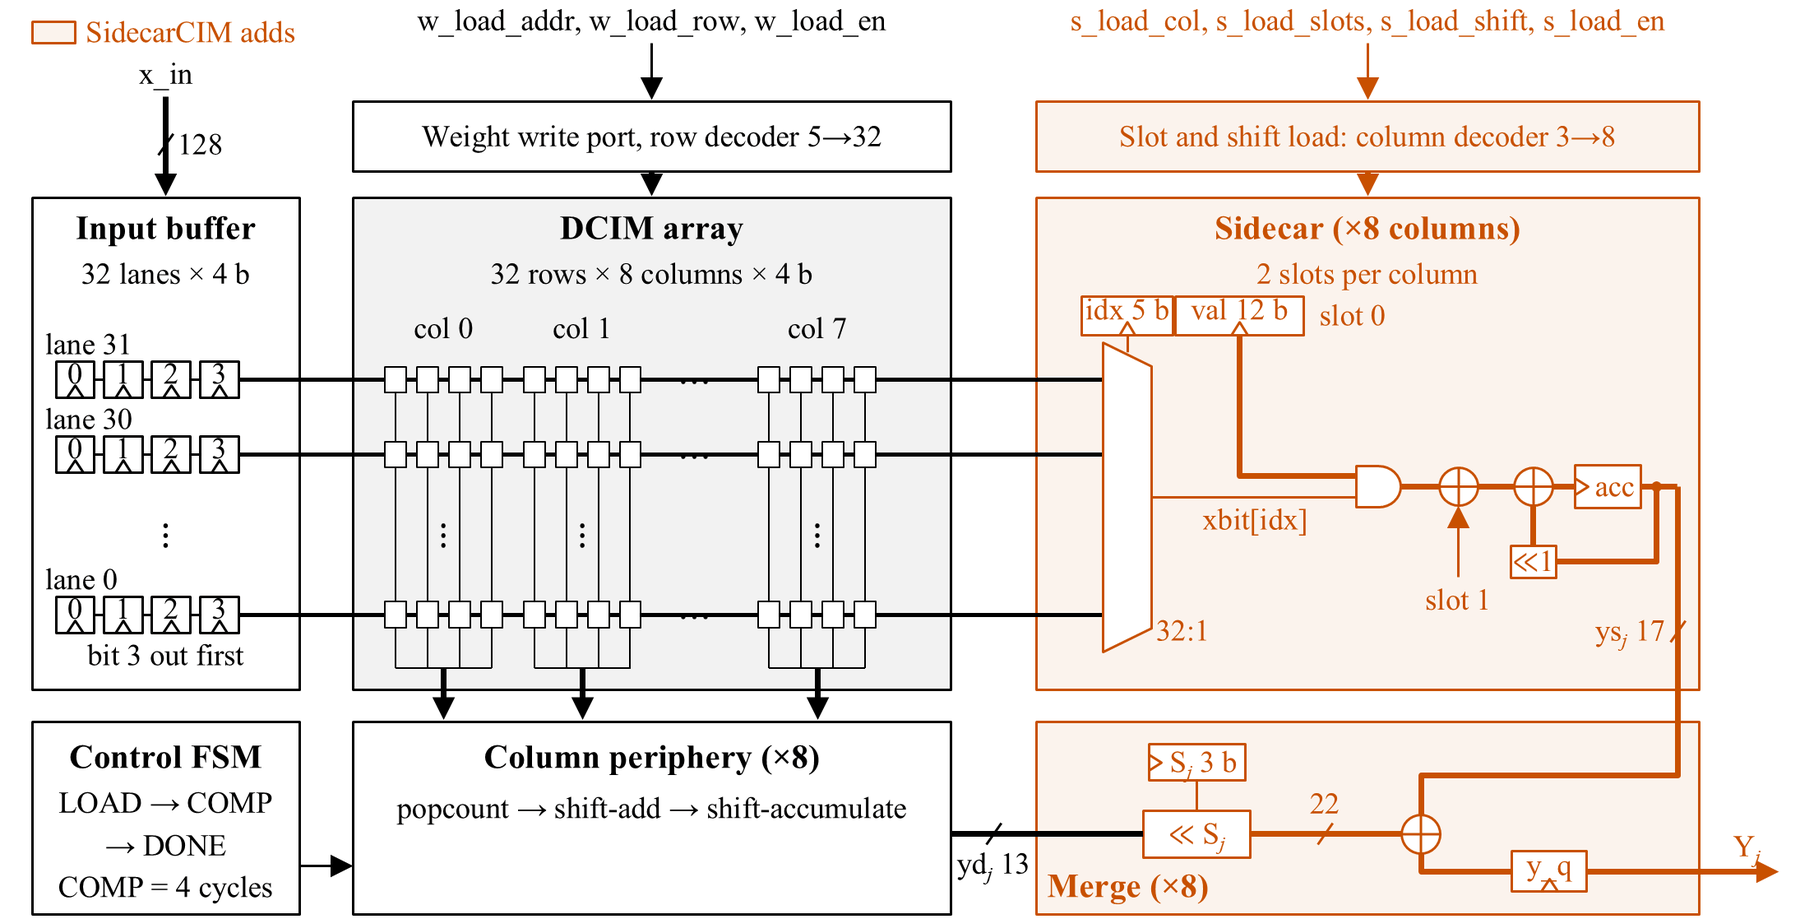

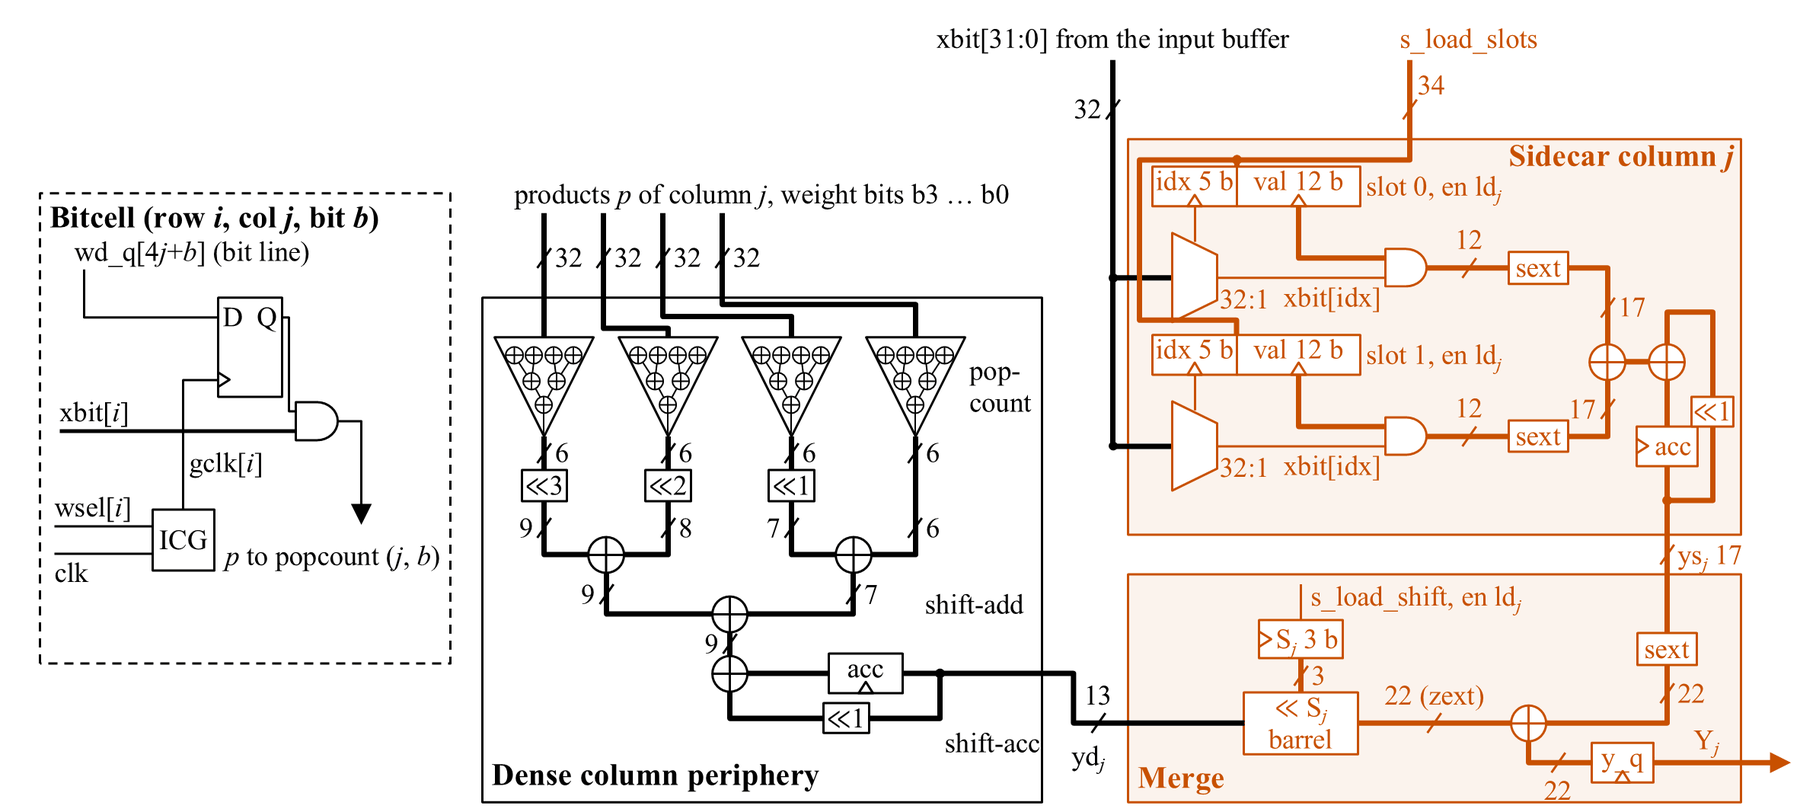

In [6]:
say("""
## II. Circuit

In SidecarCIM, the dense core is a bit-serial DCIM array following Chih
*et al.* [1]. In each cycle it ANDs one input bit-plane with the
stored weight bits, counts the ones per column and shift-accumulates the
result. The sidecar (orange in Fig. 1) adds {k} slots per column, each
holding a row index and a signed {vb}-bit weight (TABLE III). A
multiplexer per slot
selects the slot row's bit from the same bit-plane bus, `xbit`, so the
sidecar accumulates over the same bit-planes as the dense core and both
finish after {ab} cycles. The merge adds the shifted dense result and
the sidecar sum into one output register. This costs one cycle of
latency but keeps the throughput at one MVM per {c_iso} cycles.
""")
show_png("schematic/fig1a_macro.png", 1800)
show_png("schematic/fig1b_column.png", 1800)

**Fig. 1.** SidecarCIM macro, drawn from the RTL. (a) Block level: each input lane is a 4-bit shift register that sends one bit of x[i] per cycle, most significant bit first, along `xbit` to both the dense array and the sidecar (orange). The sidecar therefore needs no second input register and finishes in the same cycles. (b) One column at circuit level: each weight bit is a D flip-flop on its row's gated clock, the dense path counts and shift-accumulates the products, each sidecar slot picks its row's bit with a 32:1 multiplexer, and the merge adds the shifted dense result and the sidecar sum into the output register y_q, one edge after the array.

In [7]:
CFG = (ROOT / "flow" / SC / "config.json").read_text()
SBITS = int(re.search(r"SBITS=(\d+)", CFG).group(1))
IDXB = int(math.log2(N_IN))
display(Markdown("**TABLE III.** Sidecar fields per column of the final "
                 "build; the %d slots load together as one %d-bit word."
                 % (K, K * (IDXB + VB))))
show_table(pd.DataFrame([
    ["idx (per slot)", IDXB, "row of the slot's weight; selects its bit "
     "of xbit"],
    ["val (per slot)", VB, "signed weight value"],
    ["S_j (per column)", SBITS, "left shift applied to the dense result "
     "in the merge"]], columns=["Field", "Bits", "Use"]))

**TABLE III.** Sidecar fields per column of the final build; the 2 slots load together as one 34-bit word.

| Field | Bits | Use |
| --- | --- | --- |
| idx (per slot) | 5 | row of the slot's weight; selects its bit of xbit |
| val (per slot) | 12 | signed weight value |
| S_j (per column) | 3 | left shift applied to the dense result in the merge |

Fig. 2 shows the RTL simulation of the final build. In both MVMs, `valid` rises 5 edges after `start`: 4 bit-planes plus the output register.

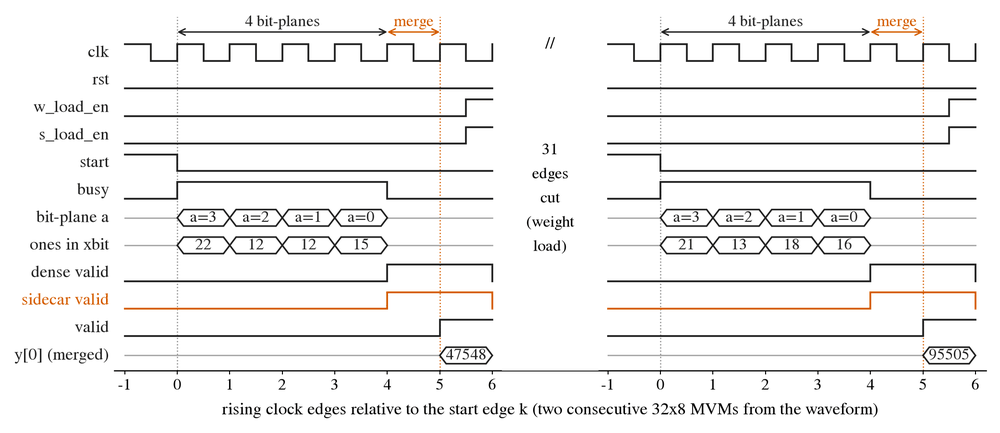

In [8]:
say("""
Fig. 2 shows the RTL simulation of the final build. In both MVMs,
`valid` rises {lat_sc} edges after `start`: {ab} bit-planes plus the
output register.
""")
show_png("fig_timing.png", 1000)

**Fig. 2.** RTL simulation of the final build, two MVMs back to back with the loading cycles cut out. Dense and sidecar finish on the same edge; the merge register shows `valid` one edge later.

All designs are implemented with one LibreLane flow on SKY130 [13], [14] and its open toolchain [15]-[19], with a 30 ns clock, identical settings and weights stored in clock-gated standard-cell flip-flops. Every design meets setup and hold at every signed-off corner, and DRC and LVS are clean for all 11 layouts. Power is estimated after layout with OpenSTA, using gate-level switching activity from real GPT-2 tiles.

Fig. 3 shows the final layout with cells colored by RTL module. Together, the 4-bit array and the sidecar take 3.0 % more area than W6A4. The final build reaches 43.8 MHz at the worst corner, at or above W6A4 and W8A4.

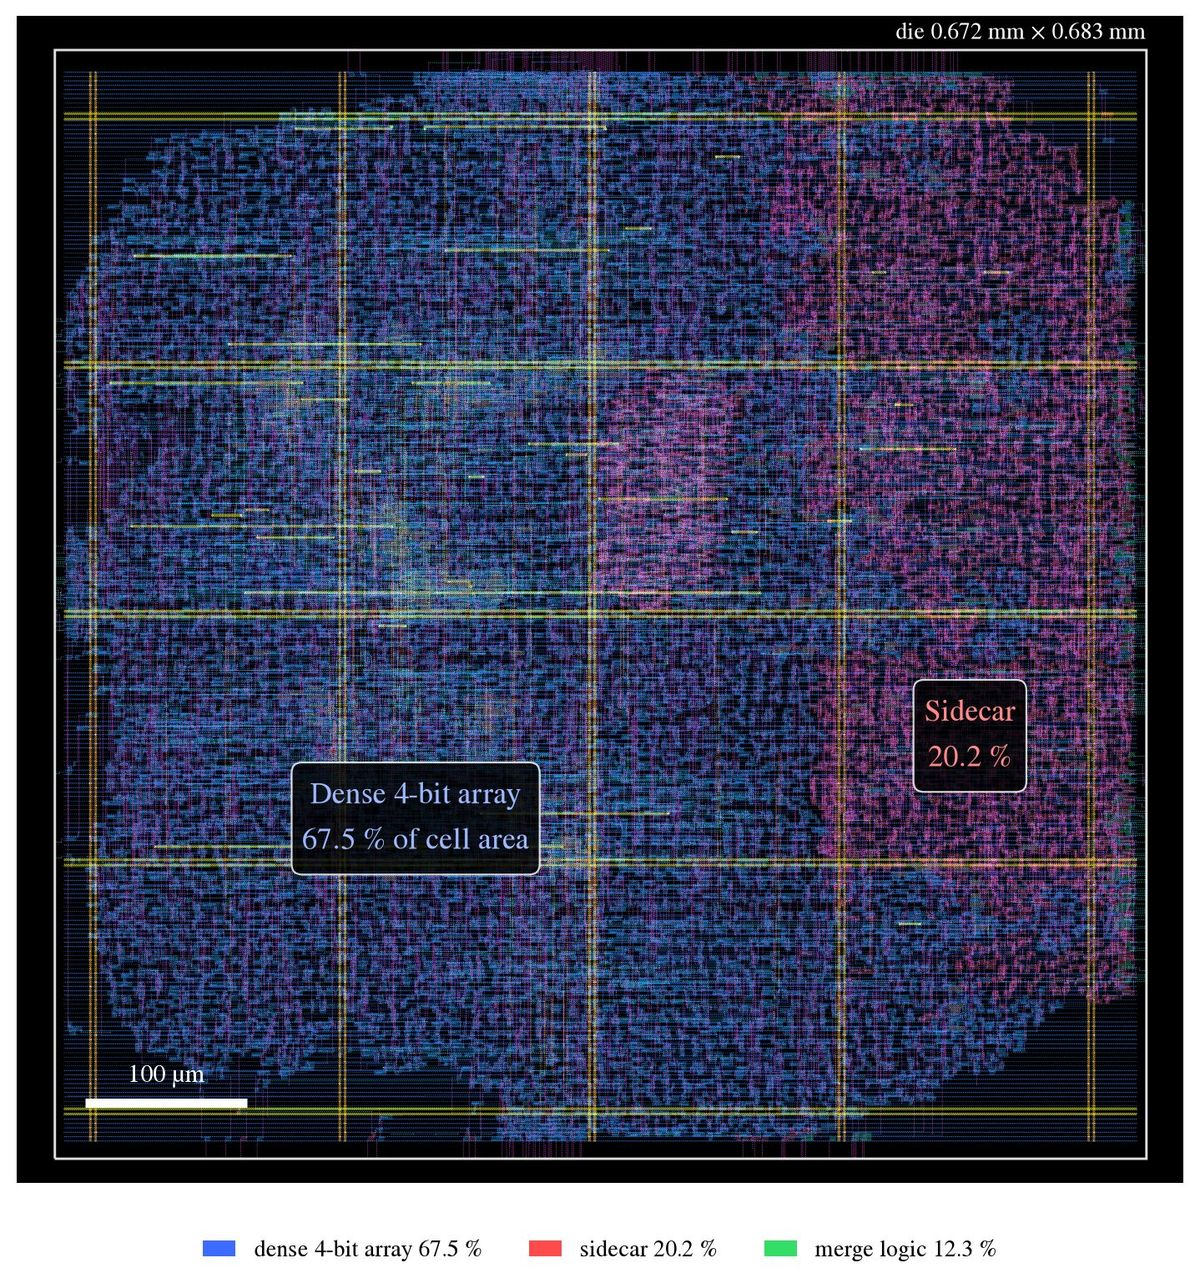

In [9]:
say("""
All designs are implemented with one LibreLane flow on SKY130
[13], [14] and its open toolchain
[15]-[19], with a {clk} ns clock,
identical settings and weights stored in clock-gated standard-cell
flip-flops. {timing}, and DRC and LVS are clean for all {n_circ}
layouts. Power is estimated after layout with OpenSTA, using gate-level
switching activity from real GPT-2 tiles.

Fig. 3 shows the final layout with cells colored by RTL module.
Together, the 4-bit array and the sidecar take {w6_area:.1f} % more area
than W6A4. The final build reaches {fmax_sc:.1f} MHz at the worst corner,
at or above W6A4 and W8A4.
""")
show_im(shrink(PILImage.open(RES / "fig_layout.jpg"), 1200),
        jpeg=True)

**Fig. 3.** Final SidecarCIM layout (KLayout render), cells colored by RTL module, with each module's share of the synthesis cell area. The scale bar and die size come from the LibreLane sign-off (`results/signoff/`).

## III. Verification

One integer reference connects the accuracy results to the implemented circuit. cocotb and Icarus Verilog [20], [21] compare each design bit for bit against `python/golden.py`, and injected faults confirm that the tests detect errors. The accuracy runs check every replaced layer against the same reference, tile by tile. The gate-level simulation of each netlist, which also provides the activity for the power estimate, matches the RTL at every clock edge.

The cells below reimplement the reference in numpy and replay the stored test vectors. With `RUN_SIM = True`, the last of them simulates the final build's RTL with cocotb and Icarus Verilog in this session.

In [10]:
def dcim_dot(w, x, wbits, abits):
    """Bit-serial dense MVM (same as python/golden.py dcim_dot)."""
    w = np.asarray(w, dtype=np.int64)
    x = np.asarray(x, dtype=np.int64)
    acc_ = np.zeros(w.shape[1], dtype=np.int64)
    for a in range(abits - 1, -1, -1):
        xb = (x >> a) & 1
        part = np.zeros(w.shape[1], dtype=np.int64)
        for b in range(wbits):
            part += (((w >> b) & 1) & xb[:, None]).sum(axis=0) << b
        acc_ = (acc_ << 1) + part
    return acc_


def sidecar_dot(idx, val, x, abits):
    """Bit-serial sidecar sum (same as golden.py sidecar_dot)."""
    idx, val = np.asarray(idx), np.asarray(val, dtype=np.int64)
    x = np.asarray(x, dtype=np.int64)
    acc_ = np.zeros(val.shape[1], dtype=np.int64)
    for a in range(abits - 1, -1, -1):
        acc_ = (acc_ << 1) + (val * ((x[idx] >> a) & 1)).sum(axis=0)
    return acc_


if RUN_FULL:
    sys.path.insert(0, str(ROOT / "python"))
    import golden
    rng = np.random.default_rng(0)
    for _ in range(200):
        w = rng.integers(0, 2 ** WBITS, (N_IN, N_OUT))
        x = rng.integers(0, 2 ** ABITS, N_IN)
        assert np.array_equal(dcim_dot(w, x, WBITS, ABITS),
                              golden.dcim_dot(w, x, WBITS, ABITS))
    print("matches python/golden.py on random cases")

In [11]:
REP = (ROOT / "tests" / "report.md").read_text()
# the newest sign-off of the final (clock-gated flip-flop) builds
CGS_REP = REP.split("# Clock-gating re-sign-off", 1)[1]
CGS_REP = CGS_REP.split("## Results, flip-flop builds", 1)[1]
CGS_REP = CGS_REP.split("\n## ", 1)[0]


def counts(label):
    """Its row of the results table: the 'a/b' counts, in order."""
    row = [ln for ln in CGS_REP.splitlines() if ln.startswith("| " + label)]
    assert len(row) == 1 and "FAIL" not in row[0], label
    return re.findall(r"[\d,]+/[\d,]+", row[0])


c = counts("dcim_core FF")
# clock-gating directed tests
T2 = [["dcim_core W4A4"] + c[:4] + [" + ".join(c[4:])]]
# the same-cycle dense rivals: "# W8A4 / W6A4 sign-off"
W_REP = REP.split("# W8A4 / W6A4 sign-off", 1)[1]
W_REP = W_REP.split("## Results", 1)[1].split("\n## ", 1)[0]
assert "FAIL" not in W_REP
WC = [re.findall(r"[\d,]+/[\d,]+", ln) for ln in W_REP.splitlines()
      if ln.startswith("| ") and "PASS" in ln]
T2.append(["dcim_core W8A4 / W6A4"] + [" / ".join(c) for c in WC])
# the final build: "# PIPE_MERGE + SBITS=3 sign-off"
S3 = REP.split("# PIPE_MERGE + SBITS=3 sign-off", 1)[1]
S3 = S3.split("## Results", 1)[1].split("\n## ", 1)[0]
S3C = {ln.split("|")[1].strip(): re.findall(r"[\d,]+/[\d,]+", ln)[0]
       for ln in S3.splitlines() if ln.startswith("| ") and "PASS" in ln}
T2.append(["SidecarCIM final build"] + [
    S3C[k] for k in ("corners (natural row order)",
                     "random (shuffled rows)",
                     "real_layer (reverse row order)", "protocol (9)")] + [
    " + ".join(S3C[k] for k in ("clock-gating directed (5)",
                                "pipeline directed (5, every edge vs model)",
                                "vb_extremes"))])
# directed tests: "5/5 + 5/5 + 32/32" -> one passed/total pair
DIR = [tuple(int(v) for v in p.split("/")) for p in T2[-1][5].split(" + ")]
SIGNOFF = tuple(T2[-1][1:5]) + ("%d/%d" % tuple(map(sum, zip(*DIR))),)

In [12]:
LIMIT = None if RUN_FULL else 500


def check(name, fn):
    d = np.load(VEC / (name + ".npz"))
    n = len(d["x"]) if LIMIT is None else min(LIMIT, len(d["x"]))
    return [name, n, sum(not np.array_equal(fn(d, c), d["y"][c])
                         for c in range(n))]


def dense(bits):
    return lambda d, c: dcim_dot(d["w"][c], d["x"][c], bits, bits)


def merged(d, c):
    y = dcim_dot(d["w"][c], d["x"][c], WBITS, ABITS)
    y = y << d["S"][c].astype(np.int64)
    return y + sidecar_dot(d["idx"][c], d["val"][c], d["x"][c], ABITS)


rows = [check(n, dense(WBITS)) for n in ("corners", "random", "real_layer")]
rows += [check(n, merged) for n in (
    "sidecar_corners", "sidecar_random", "sidecar_real_layer",
    "sidecar_s3_corners")]
assert not any(r[2] for r in rows), rows
# LibreLane sign-off of every layout, as the tools wrote it
SO = sorted((RES / "signoff").glob("*/metrics.json"))
MET = {p.parent.name: json.loads(p.read_text()) for p in SO}
DRC = sum(m["magic__drc_error__count"] + m["klayout__drc_error__count"]
          for m in MET.values())
LVS = sum(m["design__lvs_error__count"] for m in MET.values())
SLACK = all(m["timing__setup__ws"] > 0 and m["timing__hold__ws"] > 0
            for m in MET.values())
SCB = [m for d, m in MET.items() if d.startswith("sidecarcim")]
ANT = sum(m["antenna__violating__nets"] for m in SCB)
assert len(MET) == 11 and DRC == 0 and LVS == 0 and SLACK and ANT == 0
display(Markdown(
    "The LibreLane sign-off reports of all %d layouts (`results/signoff/`) "
    "show no DRC error in Magic or KLayout, no LVS error and positive "
    "worst-case setup and hold slack, and the %d SidecarCIM builds have no "
    "antenna violation." % (len(MET), len(SCB))))
display(Markdown(
    "RTL sign-off of the final build (`tests/report.md`): %s corner, %s "
    "random and %s real-layer cases, %s protocol tests and %s directed "
    "tests pass, and the W4A4, W6A4 and W8A4 arrays pass the same suite. "
    "Replaying %s of the stored vectors against the reference above gives "
    "no mismatch." % (SIGNOFF + ("{:,}".format(sum(r[1] for r in rows)),))))

The LibreLane sign-off reports of all 11 layouts (`results/signoff/`) show no DRC error in Magic or KLayout, no LVS error and positive worst-case setup and hold slack, and the 4 SidecarCIM builds have no antenna violation.

RTL sign-off of the final build (`tests/report.md`): 26/26 corner, 10,000/10,000 random and 4,096/4,096 real-layer cases, 9/9 protocol tests and 42/42 directed tests pass, and the W4A4, W6A4 and W8A4 arrays pass the same suite. Replaying 2,086 of the stored vectors against the reference above gives no mismatch.

In [13]:
if RUN_SIM:
    import shutil
    import subprocess
    if shutil.which("iverilog") is None:            # Colab runs as root
        subprocess.run(["apt-get", "-qq", "install", "-y", "iverilog"],
                       check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "--disable-pip-version-check", "cocotb>=1.9", "pyyaml"],
                   check=True, capture_output=True)
    path = os.path.dirname(sys.executable) + os.pathsep
    env = dict(os.environ, TOP_REAL_LIMIT="500",
               PATH=path + os.environ.get("PATH", ""))
    sim = subprocess.run(["make", "-C", "tests", "top_ff_pipe_s3",
                          "DCIM_RANDOM_LIMIT=500"], cwd=ROOT, env=env,
                         capture_output=True, text=True)
    log = sim.stdout + sim.stderr
    for name, verdict in re.findall(
            r"test_sidecarcim_top\.(\w+) (passed|failed)", log):
        print("%-28s %s" % (name, verdict))
    total = re.search(r"TESTS=\d+ PASS=\d+ FAIL=\d+ SKIP=\d+", log)
    print(total.group(0) if total else "no summary")
    assert sim.returncode == 0, log[-4000:]

## IV. Comparison with dense arrays

Every GPT-2 small [22] `mlp.c_fc` layer and every Qwen2.5-0.5B [23] gate and up projection runs through the integer path, covering 23 % and 42 % of their linear MACs. The remaining layers stay in FP32. Calibration uses WikiText-2 [24], and accuracy is measured on the full test split (280 and 292 windows) with paired t-tests against SidecarCIM. The dense baselines use wider weights with the same 4-bit inputs, so all designs run one MVM per 5 cycles in the same flow at the same clock. TABLE I lists the results, and Fig. 4 plots accuracy against energy.

SidecarCIM reduces perplexity relative to W6A4 by 0.52 on GPT-2 and 0.32 on Qwen at +2.9 % energy and +3.0 % area. Over three calibration draws the improvement ranges from 0.52 to 0.72 and from 0.23 to 0.32 ppl, with p = 0.010 and 0.009 across draws (df = 2). Relative to plain 4-bit with the same migration and clipping, SidecarCIM shrinks the accuracy loss 4.7x on GPT-2 and 4.1x on Qwen.

W7A4 and W8A4 reach 0.19 to 0.30 ppl lower perplexity at a cost of at least 11 % more area and 12 % more energy. All results assume the weights stay resident in the macro.

As a trade-off, SidecarCIM closes 72 % (GPT-2) and 52 % (Qwen) of the accuracy gap between W6A4 and W8A4 for 2.9 % more energy and 3.0 % more area, where W8A4 pays 27 % and 29 %. At equal accuracy, SidecarCIM needs 6 to 7 % less energy and area than a dense array interpolated between the measured W6A4 and W7A4 points.

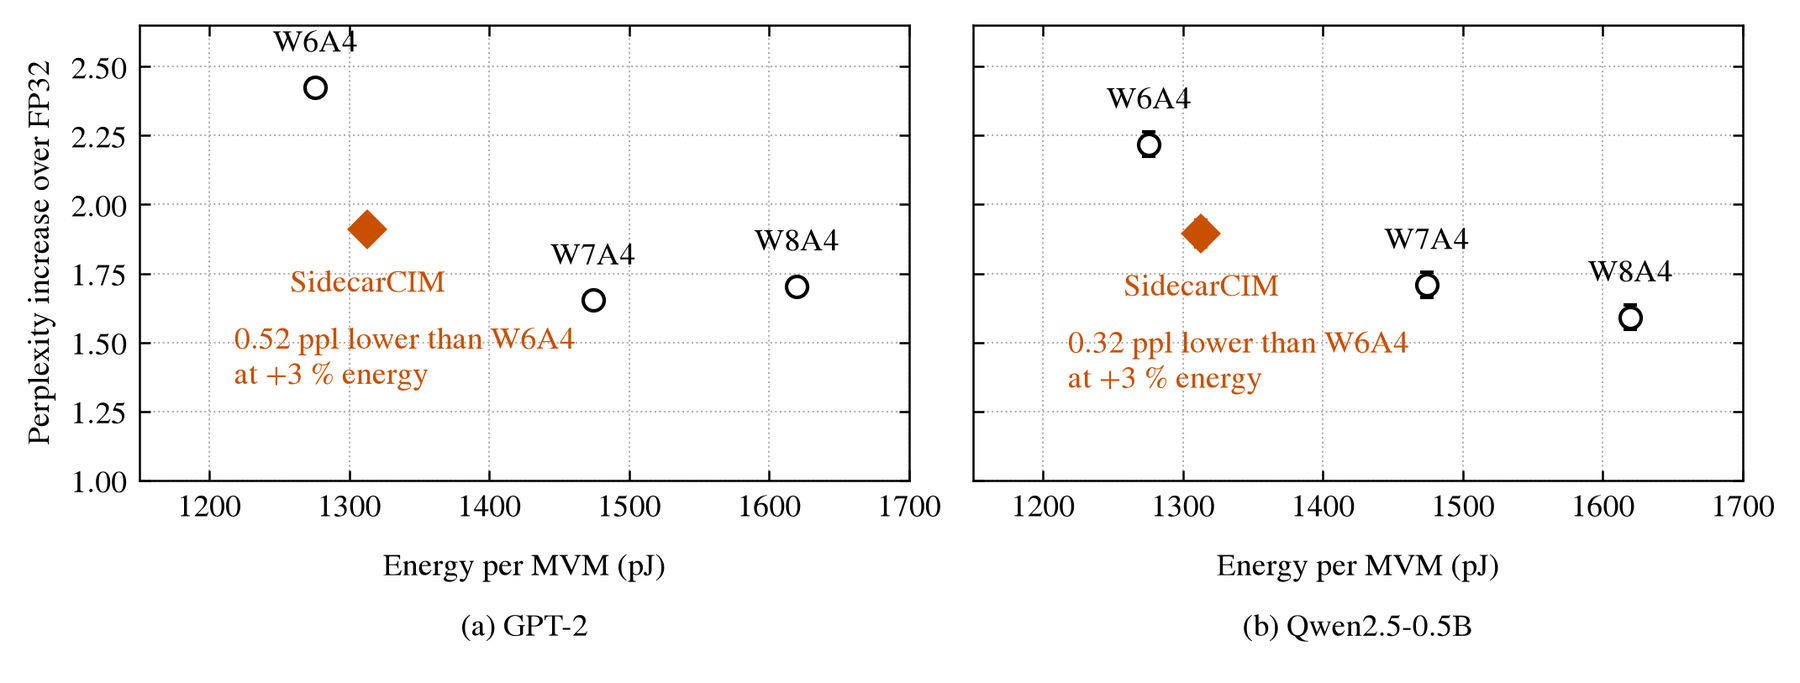

**Fig. 4.** Accuracy against energy for (a) GPT-2 and (b) Qwen2.5-0.5B: perplexity increase over FP32 on the full WikiText-2 test split (bars: paired standard error) against post-layout energy per MVM. Dense arrays in black, SidecarCIM in orange. Dense W4A4 lies off scale at +9.02 and +7.82 ppl. Data: `results/ppa.csv`, `python/out/fulltest.json`.

In [14]:
say("""
## IV. Comparison with dense arrays

Every GPT-2 small [22] `mlp.c_fc` layer and every Qwen2.5-0.5B
[23] gate and up projection runs through the integer path, covering
{gpt2_share:.0f} % and {qwen_share:.0f} % of their linear MACs. The
remaining layers stay in FP32. Calibration uses WikiText-2 [24],
and accuracy is measured on the full test split ({g_win} and {q_win}
windows) with paired t-tests against SidecarCIM. The dense baselines use
wider weights with the same 4-bit inputs, so all designs run one MVM per
{c_iso} cycles in the same flow at the same clock. TABLE I lists the
results, and Fig. 4 plots accuracy against energy.
""")
say("""
SidecarCIM reduces perplexity relative to W6A4 by {g_fw6_dp:.2f} on
GPT-2 and {q_fw6_dp:.2f} on Qwen at {w6_en:+.1f} % energy and
{w6_area:+.1f} % area. Over three calibration draws the improvement
ranges from {g_cal_w6_lo:.2f} to {g_cal_w6_hi:.2f} and from
{q_cal_w6_lo:.2f} to {q_cal_w6_hi:.2f} ppl, with p = {g_calp_w6:.3f} and
{q_calp_w6:.3f} across draws (df = 2). Relative to plain 4-bit with the
same migration and clipping, SidecarCIM shrinks the accuracy loss
{g_rat:.1f}x on GPT-2 and {q_rat:.1f}x on Qwen.

W7A4 and W8A4 reach {wide_lo:.2f} to {wide_hi:.2f} ppl lower perplexity
at a cost of at least {w7_area:.0f} % more area and {w7_en:.0f} % more
energy. All results assume the weights stay resident in the macro.
""")
say("""
As a trade-off, SidecarCIM closes {g_gap:.0f} % (GPT-2) and {q_gap:.0f} %
(Qwen) of the accuracy gap between W6A4 and W8A4 for {w6_en:.1f} % more
energy and {w6_area:.1f} % more area, where W8A4 pays {r8_en:.0f} % and
{r8_ar:.0f} %. At equal accuracy, SidecarCIM needs {eq_lo:.0f} to
{eq_hi:.0f} % less energy and area than a dense array interpolated between
the measured W6A4 and W7A4 points.
""")
show_png("fig_headline.png", 1800)
say("""
**Fig. 4.** Accuracy against energy for (a) GPT-2 and (b) Qwen2.5-0.5B:
perplexity increase over FP32 on the full WikiText-2 test split (bars:
paired standard error) against post-layout energy per MVM. Dense arrays
in black, SidecarCIM in orange. Dense W4A4 lies off scale at
+{g_fmc:.2f} and +{q_fmc:.2f} ppl. Data: `results/ppa.csv`,
`python/out/fulltest.json`.
""")

In [15]:
say("""
## V. Predicting which models benefit

The sidecar helps a model whose migrated weights contain a few values far
larger than the rest, because those values would otherwise stretch the
4-bit range of every column they sit in. It cannot help a model whose
weights are spread evenly. The excess kurtosis of the migrated weights
measures exactly this: it is near 0 for a bell-shaped distribution and
grows with the share of extreme values. It needs only calibration data
and a few seconds of Python, with no hardware and no accuracy run.

Across {pr_n} models (four TinyStories models [25], GPT-2,
Qwen2.5-0.5B, three SmolLM2 [26], two OPT [27], three Pythia
[28] and {pro_n} held-out models: {pro_names}), one split at
{k_split:.2f} decides the choice (TABLE IV). Above it, SidecarCIM
is better than W6A4 on {above_gain} of {above_n} models and worse on none.
At or below it, W6A4 is better on {below_lose} of {below_n}. The rule was
frozen before the {pro_n} held-out models ran and predicted the direction
of the change for all of them, so a designer can decide from one number,
before tape-out, whether a model should run on SidecarCIM.
""")
MODEL_NAME = {
    "gpt2": "GPT-2", "gpt2-medium": "GPT-2-medium",
    "gpt2-large": "GPT-2-large", "qwen2.5-0.5b": "Qwen2.5-0.5B",
    "qwen2.5-1.5b": "Qwen2.5-1.5B", "bloom-1b1": "BLOOM-1B1",
    "opt-125m": "OPT-125M", "opt-350m": "OPT-350M",
    "pythia-160m": "Pythia-160M", "pythia-410m": "Pythia-410M",
    "pythia-1b": "Pythia-1B", "smollm2-135m": "SmolLM2-135M",
    "smollm2-360m": "SmolLM2-360M", "smollm2-1.7b": "SmolLM2-1.7B",
    "tinystories-1m": "TinyStories-1M", "tinystories-3m": "TinyStories-3M",
    "tinystories-8m": "TinyStories-8M", "tinystories-33m": "TinyStories-33M"}
WIN = {"gain": "SidecarCIM", "loss": "W6A4", "none": "no difference"}


def model_row(q):
    r = [MODEL_NAME.get(q["model"], q["model"]), "%.1f" % q[KUR],
         WIN[sig(q)], "%+.2f" % q["gain_over_W6A4_ppl"]]
    return ["**%s**" % c for c in r] if sig(q) == "gain" else r


TM = [model_row(q) for q in sorted(ABOVE, key=lambda q: -q[KUR])]
TM.append(["*split at %.2f*" % KSPL, "", "", ""])
TM += [model_row(q) for q in sorted(BELOW, key=lambda q: -q[KUR])]
display(Markdown("**TABLE IV.** SidecarCIM against dense W6A4 on all %d "
                 "models, sorted by the excess kurtosis of the migrated "
                 "weights. Bold: SidecarCIM better (p < 0.05, paired "
                 "t-test). Gain is the perplexity improvement over W6A4."
                 % len(PRD["points"])))
show_table(pd.DataFrame(TM, columns=["Model", "Excess kurtosis",
                                     "Better design", "Gain (ppl)"]))
say("""
The largest activation alone is a weaker guide: a rule based on it
missed BLOOM-1B1 among the held-out models. For SmolLM2-1.7B, the
attention-sink token [29] stays in FP, which is exact because token 0
attends only to itself.
""")

## V. Predicting which models benefit

The sidecar helps a model whose migrated weights contain a few values far larger than the rest, because those values would otherwise stretch the 4-bit range of every column they sit in. It cannot help a model whose weights are spread evenly. The excess kurtosis of the migrated weights measures exactly this: it is near 0 for a bell-shaped distribution and grows with the share of extreme values. It needs only calibration data and a few seconds of Python, with no hardware and no accuracy run.

Across 18 models (four TinyStories models [25], GPT-2, Qwen2.5-0.5B, three SmolLM2 [26], two OPT [27], three Pythia [28] and 4 held-out models: Qwen2.5-1.5B, GPT-2-medium, BLOOM-1B1, GPT-2-large), one split at 8.88 decides the choice (TABLE IV). Above it, SidecarCIM is better than W6A4 on 7 of 10 models and worse on none. At or below it, W6A4 is better on 7 of 8. The rule was frozen before the 4 held-out models ran and predicted the direction of the change for all of them, so a designer can decide from one number, before tape-out, whether a model should run on SidecarCIM.

**TABLE IV.** SidecarCIM against dense W6A4 on all 18 models, sorted by the excess kurtosis of the migrated weights. Bold: SidecarCIM better (p < 0.05, paired t-test). Gain is the perplexity improvement over W6A4.

| Model | Excess kurtosis | Better design | Gain (ppl) |
| --- | --- | --- | --- |
| **Qwen2.5-0.5B** | **48.1** | **SidecarCIM** | **+0.32** |
| **Qwen2.5-1.5B** | **47.6** | **SidecarCIM** | **+0.14** |
| **SmolLM2-360M** | **42.6** | **SidecarCIM** | **+0.57** |
| **GPT-2** | **40.0** | **SidecarCIM** | **+0.52** |
| **BLOOM-1B1** | **39.2** | **SidecarCIM** | **+0.24** |
| **OPT-125M** | **32.0** | **SidecarCIM** | **+0.27** |
| GPT-2-medium | 24.2 | no difference | +0.01 |
| Pythia-160M | 18.7 | no difference | -0.02 |
| Pythia-1B | 13.8 | no difference | +0.02 |
| **SmolLM2-1.7B** | **9.7** | **SidecarCIM** | **+4.34** |
| *split at 8.88* |  |  |  |
| SmolLM2-135M | 8.1 | W6A4 | -0.25 |
| Pythia-410M | 3.8 | W6A4 | -0.20 |
| OPT-350M | 2.8 | W6A4 | -0.29 |
| GPT-2-large | 1.7 | no difference | -0.03 |
| TinyStories-33M | 0.5 | W6A4 | -0.04 |
| TinyStories-8M | 0.4 | W6A4 | -0.18 |
| TinyStories-3M | 0.2 | W6A4 | -1.04 |
| TinyStories-1M | 0.2 | W6A4 | -8.87 |

The largest activation alone is a weaker guide: a rule based on it missed BLOOM-1B1 among the held-out models. For SmolLM2-1.7B, the attention-sink token [29] stays in FP, which is exact because token 0 attends only to itself.

In [16]:
say("""
## VI. Design choices and limitations

The ablations support each design choice. Weight precision limits
accuracy more than input precision: W4A8 loses {g_fw48_dp:.2f} ppl more
than SidecarCIM on GPT-2. Slots of {vb} bits perform as well as 16-bit
slots, and keeping each column's largest weights outperforms greedy
selection. The advantage grows with array height. At 128 rows,
SidecarCIM needs {r_area:.2f}x the area and {r_en:.2f}x the energy of
W6A4, with accuracy taken from short runs.

All results are post-layout estimates on SKY130; the macro has not been
fabricated. The integer path covers the MLP input projections,
{gpt2_share:.0f} % of the linear MACs of GPT-2 and {qwen_share:.0f} % of
Qwen2.5-0.5B. Fabrication, RTL sign-off of the 128-row layouts, more of
the model in the integer path and a wider model set are the next steps.

## VII. Conclusion

SidecarCIM keeps a standard bit-serial 4-bit DCIM array and moves the
few weights that need more precision into a small sidecar that shares
the array's input bit-plane. Against a dense W6A4 array at the same
clock and throughput, it lowers perplexity by {g_fw6_dp:.2f} on GPT-2
and {q_fw6_dp:.2f} on Qwen2.5-0.5B for {w6_en:+.1f} % energy and
{w6_area:+.1f} % area, and the kurtosis of the migrated weights tells in
advance which models benefit. The design is open source from RTL to
GDS.
""")

## VI. Design choices and limitations

The ablations support each design choice. Weight precision limits accuracy more than input precision: W4A8 loses 2.78 ppl more than SidecarCIM on GPT-2. Slots of 12 bits perform as well as 16-bit slots, and keeping each column's largest weights outperforms greedy selection. The advantage grows with array height. At 128 rows, SidecarCIM needs 0.89x the area and 0.83x the energy of W6A4, with accuracy taken from short runs.

All results are post-layout estimates on SKY130; the macro has not been fabricated. The integer path covers the MLP input projections, 23 % of the linear MACs of GPT-2 and 42 % of Qwen2.5-0.5B. Fabrication, RTL sign-off of the 128-row layouts, more of the model in the integer path and a wider model set are the next steps.

## VII. Conclusion

SidecarCIM keeps a standard bit-serial 4-bit DCIM array and moves the few weights that need more precision into a small sidecar that shares the array's input bit-plane. Against a dense W6A4 array at the same clock and throughput, it lowers perplexity by 0.52 on GPT-2 and 0.32 on Qwen2.5-0.5B for +2.9 % energy and +3.0 % area, and the kurtosis of the migrated weights tells in advance which models benefit. The design is open source from RTL to GDS.

## VIII. Reproducibility

Everything ran in WSL2 Ubuntu 24.04 from the folder root. Setup: `python3 -m venv .venv`, `. .venv/bin/activate` and `pip install -r requirements.txt`; LibreLane runs in Docker, and Icarus Verilog and Verilator come from apt. Then:
```text
python python/golden.py                     # reference self-test
make sim-full                               # RTL sign-off, all vectors
python python/fulltest.py gpt2              # full test split (Qwen: qwen 292)
python python/fulltest_extra.py gpt2 dense  # W7A4, W4A8 (also: calib)
python python/predictor.py fit              # which models gain
librelane --docker-no-tty --dockerized flow/<design>/config.json
python3 flow/extract_ppa.py                 # results/ppa.csv, results/gds/
cd results && python make_figures.py        # figures and tables
```
`flow/README.md` lists every laid-out design (the final build is `sidecarcim_top_ff_pipe_s3`). The flow uses SKY130 [14] (sky130A, sky130_fd_sc_hd) and LibreLane 3.0.16 [13] with Yosys 0.62, OpenROAD dcf36133a3, Magic 8.3.623, KLayout 0.30.7 and Netgen 1.5.316. Verification uses cocotb 2.1.0 [20], Icarus Verilog 12.0 [21] and Verilator 5.020 [30], with Python 3.12 (3.10 in the contest CI). The cells of this notebook read saved result files with numpy, pandas and matplotlib only, so it runs in under a minute.

## Acknowledgment

I used Claude (Anthropic) to draw the figures, check the grammar and format the notebook.

## References

[1] Y.-D. Chih *et al.*, “16.4 an 89TOPS/W and 16.3TOPS/mm² all-digital SRAM-based full-precision compute-in-memory macro in 22nm for machine-learning edge applications,” in *IEEE Int. Solid-State Circuits Conf. (ISSCC) Dig. Tech. Papers*, Feb. 2021, pp. 252-254.

[2] H. Fujiwara *et al.*, “A 5-nm 254-TOPS/W 221-TOPS/mm² fully-digital computing-in-memory macro supporting wide-range dynamic-voltage-frequency scaling and simultaneous MAC and write operations,” in *IEEE Int. Solid-State Circuits Conf. (ISSCC) Dig. Tech. Papers*, Feb. 2022, pp. 1-3.

[3] M. Ashok, S. Maji, X. Zhang, J. Cohn, and A. P. Chandrakasan, “Digital in-memory compute for machine learning applications with input and model security,” *IEEE J. Solid-State Circuits*, vol. 60, no. 9, pp. 3390-3402, Sep. 2025.

[4] T. Dettmers, M. Lewis, Y. Belkada, and L. Zettlemoyer, “LLM.int8(): 8-bit matrix multiplication for transformers at scale,” in *Proc. Adv. Neural Inf. Process. Syst. (NeurIPS)*, vol. 35, 2022, pp. 30318-30332.

[5] G. Xiao, J. Lin, M. Seznec, H. Wu, J. Demouth, and S. Han, “SmoothQuant: Accurate and efficient post-training quantization for large language models,” in *Proc. Int. Conf. Mach. Learn. (ICML)*, ser. Proc. Mach. Learn. Res., vol. 202, Jul. 2023, pp. 38087-38099.

[6] S. Kim *et al.*, “SqueezeLLM: Dense-and-sparse quantization,” in *Proc. Int. Conf. Mach. Learn. (ICML)*, ser. Proc. Mach. Learn. Res., vol. 235, Jul. 2024, pp. 23901-23923, arXiv:2306.07629.

[7] Z. Zou *et al.*, “OutlierCIM: Outlier-aware digital CIM-based LLM accelerator with hybrid-strategy quantization and unified FP-INT computation,” in *Proc. 62nd ACM/IEEE Design Autom. Conf. (DAC)*, Jun. 2025, pp. 1-7.

[8] S. He *et al.*, “A 22-nm 109.3-to-249.5-TFLOPS/W outlier-aware floating-point SRAM compute-in-memory macro for large language models,” *IEEE J. Solid-State Circuits*, vol. 61, no. 2, pp. 736-749, Feb. 2026.

[9] E. Park, D. Kim, and S. Yoo, “Energy-efficient neural network accelerator based on outlier-aware low-precision computation,” in *Proc. ACM/IEEE 45th Annu. Int. Symp. Comput. Archit. (ISCA)*, Jun. 2018, pp. 688-698.

[10] C. Guo *et al.*, “OliVe: Accelerating large language models via hardware-friendly outlier-victim pair quantization,” in *Proc. 50th Annu. Int. Symp. Comput. Archit. (ISCA)*, Jun. 2023, pp. 1-15.

[11] C. Xue *et al.*, “Oltron: Algorithm-hardware co-design for outlier-aware quantization of LLMs with inter-/intra-layer adaptation,” in *Proc. 61st ACM/IEEE Design Autom. Conf. (DAC)*, Jun. 2024, pp. 1-6.

[12] W. Park *et al.*, “A 5.99 TFLOPS/W heterogeneous CIM-NPU architecture for an energy efficient floating-point DNN acceleration,” in *Proc. IEEE Int. Symp. Circuits Syst. (ISCAS)*, May 2023, pp. 1-4.

[13] LibreLane contributors, “LibreLane: ASIC implementation flow, successor of OpenLane 2,” <https://github.com/librelane/librelane>; documentation <https://librelane.readthedocs.io>, version 3.0.16 (released 2026-10-06). Accessed 2026-10-11.

[14] SkyWater Technology and Google, “SkyWater SKY130 open-source process design kit,” <https://github.com/google/skywater-pdk>; documentation <https://skywater-pdk.readthedocs.io>, sky130A built from open\_pdks commit 8afc8346a5 (<https://github.com/fossi-foundation/open-pdks>) and installed with ciel. Accessed 2026-10-11.

[15] Yosys contributors, “Yosys open synthesis suite,” <https://github.com/YosysHQ/yosys>, version 0.62 (git 7326bb7d). Accessed 2026-10-11.

[16] The OpenROAD Project, “OpenROAD: open-source physical design and timing/power analysis,” <https://github.com/The-OpenROAD-Project/OpenROAD>; documentation <https://openroad.readthedocs.io>, commit dcf36133a3 (2026-02-17), the build shipped in the LibreLane 3.0.16 image; no tagged release. Accessed 2026-10-11.

[17] Magic contributors, “Magic VLSI layout tool,” <https://github.com/RTimothyEdwards/magic>; <http://opencircuitdesign.com/magic/>, version 8.3.623. Accessed 2026-10-11.

[18] KLayout contributors, “KLayout layout viewer and editor,” <https://github.com/KLayout/klayout>; <https://www.klayout.de>, version 0.30.7. Accessed 2026-10-11.

[19] Netgen contributors, “Netgen LVS tool,” <https://github.com/RTimothyEdwards/netgen>; <http://opencircuitdesign.com/netgen/>, version 1.5.316. Accessed 2026-10-11.

[20] cocotb contributors, “cocotb: coroutine-based co-simulation testbench environment,” <https://github.com/cocotb/cocotb>; documentation <https://docs.cocotb.org>, version 2.1.0 (released 2026-08-30). Accessed 2026-10-11.

[21] Icarus Verilog contributors, “Icarus Verilog,” <https://github.com/steveicarus/iverilog>, version 12.0 (Ubuntu 24.04 package; upstream latest is 13.0). Accessed 2026-10-11.

[22] A. Radford, J. Wu, R. Child, D. Luan, D. Amodei, and I. Sutskever, “Language models are unsupervised multitask learners,” OpenAI, Tech. Rep., 2019. [Online]. Available: <https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf>

[23] Qwen Team, “Qwen2.5 technical report,” arXiv:2412.15115, Dec. 2024.

[24] S. Merity, C. Xiong, J. Bradbury, and R. Socher, “Pointer sentinel mixture models,” arXiv:1609.07843, Sep. 2016.

[25] R. Eldan and Y. Li, “TinyStories: How small can language models be and still speak coherent English?” arXiv:2305.07759, 2023.

[26] L. B. Allal *et al.*, “SmolLM2: When smol goes big, data-centric training of a small language model,” arXiv:2502.02737, 2025.

[27] S. Zhang *et al.*, “OPT: Open pre-trained transformer language models,” arXiv:2205.01068, 2022.

[28] S. Biderman *et al.*, “Pythia: A suite for analyzing large language models across training and scaling,” in *Int. Conf. Machine Learning (ICML)*, 2023, arXiv:2304.01373.

[29] G. Xiao, Y. Tian, B. Chen, S. Han, and M. Lewis, “Efficient streaming language models with attention sinks,” in *Int. Conf. Learning Representations (ICLR)*, 2024, arXiv:2309.17453.

[30] Verilator contributors, “Verilator,” <https://github.com/verilator/verilator>; <https://www.veripool.org/verilator/>, version 5.020 (Debian package 5.020-1). Accessed 2026-10-11.